# Customer Churn Prediction
## Team: DataMinds

---

## Notebook 2: Feature Engineering, Model Building & Evaluation

---

## Section 1: Introduction

This notebook continues from where Notebook 1 ended. The EDA has given us strong clues about which variables drive churn. We now:

1. **Preprocess** the data — fix types, encode categories, scale numerics
2. **Split** into 70% training and 30% test sets
3. **Select features** using Recursive Feature Elimination (RFE) with Logistic Regression
4. **Build** an iterative GLM Binomial model (Statsmodels) with VIF-based feature pruning
5. **Determine** the optimal 0.30 decision threshold using Sensitivity/Specificity analysis
6. **Evaluate** on the unseen test set
7. **Analyze** feature impact and generate business insights
8. **Save** the final trained model as `models/churn_model.joblib`

---
## Section 2: Importing Libraries

In [1]:
# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
warnings.filterwarnings('ignore')

# Machine Learning
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn import metrics
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, precision_recall_curve
)
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Model saving
import joblib

# ── Presentation Style ──────────────────────────────────────────
plt.rcParams['figure.dpi']      = 100
plt.rcParams['axes.titlesize']  = 14
plt.rcParams['axes.labelsize']  = 12
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11
plt.rcParams['font.family']     = 'DejaVu Sans'

PALETTE      = ['#2196F3', '#F44336']
EXPORT_DPI   = 300
BASE_REPORT_DIR = '..' if os.path.exists(os.path.join('..', 'data')) else '.'
EVAL_DIR     = os.path.join(BASE_REPORT_DIR, 'reports', 'model_evaluation')
GRAPH_DIR    = os.path.join(BASE_REPORT_DIR, 'reports', 'important_graphs')
os.makedirs(EVAL_DIR, exist_ok=True)
os.makedirs(GRAPH_DIR, exist_ok=True)

print("Libraries loaded successfully.")

Libraries loaded successfully.


---
## Section 3: Load Preprocessed Dataset

In [2]:
# Load the merged dataset saved by Notebook 1
# Auto-detect preprocessed data path (supports local folder structure and flat Google Colab upload)
if os.path.exists(os.path.join('..', 'data', 'preprocessed', 'telecom_cleaned.csv')):
    PREPROCESSED_PATH = os.path.join('..', 'data', 'preprocessed', 'telecom_cleaned.csv')
elif os.path.exists(os.path.join('data', 'preprocessed', 'telecom_cleaned.csv')):
    PREPROCESSED_PATH = os.path.join('data', 'preprocessed', 'telecom_cleaned.csv')
elif os.path.exists('telecom_cleaned.csv'):
    PREPROCESSED_PATH = 'telecom_cleaned.csv'
else:
    PREPROCESSED_PATH = os.path.join('..', 'data', 'preprocessed', 'telecom_cleaned.csv')
telecom = pd.read_csv(PREPROCESSED_PATH)

print(f"Dataset loaded: {telecom.shape}")
telecom.head()

Dataset loaded: (7043, 21)


,customerID,tenure,PhoneService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,gender,...,Partner,Dependents,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,1,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,Female,...,Yes,No,No phone service,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,34,Yes,One year,No,Mailed check,56.95,1889.5,No,Male,...,No,No,No,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,2,Yes,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,Male,...,No,No,No,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,45,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,Male,...,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,2,Yes,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,Female,...,No,No,No,Fiber optic,No,No,No,No,No,No


---
## Section 4: Data Preprocessing and Feature Engineering

We follow the exact preprocessing steps from the instructor's notebook.

### STEP 1: Row-Level Data Cleaning & Target Isolation

In [3]:
# 1. TotalCharges is stored as object (string) — coerce non-numeric entries to NaN
telecom['TotalCharges'] = pd.to_numeric(telecom['TotalCharges'], errors='coerce')
print(f"TotalCharges NaN count after coerce: {telecom['TotalCharges'].isnull().sum()}")

TotalCharges NaN count after coerce: 11


In [4]:
# 2. Drop the rows where TotalCharges became NaN (customers with 0 tenure = data entry blanks)
telecom = telecom.dropna(subset=['TotalCharges'])
print(f"Dataset after dropping NaN TotalCharges: {telecom.shape}")

Dataset after dropping NaN TotalCharges: (7032, 21)


In [5]:
# 3. Map binary Yes/No columns to 1/0
varlist = ['PhoneService', 'PaperlessBilling', 'Churn', 'Partner', 'Dependents']
telecom[varlist] = telecom[varlist].apply(lambda col: col.map({'Yes': 1, 'No': 0}))

print("Binary encoding complete. Sample:")
telecom[varlist].head()

Binary encoding complete. Sample:


,PhoneService,PaperlessBilling,Churn,Partner,Dependents
0,0,1,0,1,0
1,1,0,0,0,0
2,1,1,1,0,0
3,0,0,0,0,0
4,1,1,1,0,0


In [6]:
# 4. Separate features and target variable
X = telecom.drop(columns=['Churn', 'customerID'])
y = telecom['Churn']

# Baseline churn rate
baseline_churn = round((y.sum() / len(y)) * 100, 2)
print(f"Baseline Data Churn Rate: {baseline_churn}%")

Baseline Data Churn Rate: 26.58%


> The baseline churn rate of approximately **26.58%** tells us that if we naively predicted "No Churn" for every customer, we would be correct 73.42% of the time. Our model must do better than this naive baseline — especially for the minority class.

### STEP 2: Outlier Check (Numerical Variables)

In [7]:
# Checking for extreme values in continuous features
num_telecom = telecom[['tenure', 'MonthlyCharges', 'TotalCharges']]
num_telecom.describe(percentiles=[.25, .5, .75, .90, .95, .99])

,tenure,MonthlyCharges,TotalCharges
count,7032.000000,7032.000000,7032.000000
mean,32.421786,64.798208,2283.300441
std,24.545260,30.085974,2266.771362
min,1.000000,18.250000,18.800000
25%,9.000000,35.587500,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.862500,3794.737500
90%,69.000000,102.645000,5976.640000
95%,72.000000,107.422500,6923.590000
99%,72.000000,114.734500,8039.883000


> **Observation:** The percentile progression is smooth and gradual across all three numerical features. There are no extreme outlier jumps between the 95th and 99th percentile, confirming that **no outlier treatment is necessary** for this dataset.

---
## Section 5: Train-Test Split (70:30)

We follow the instructor's 70:30 split strategy with `random_state=100` for reproducibility.

**Why split?** The test set acts as a simulation of real-world unseen data. If we train and evaluate on the same data, we cannot trust the results — the model would appear perfect but fail in production.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, test_size=0.3, random_state=100
)

# Defensive copy to avoid slice-assignment warnings
X_train = X_train.copy()
X_test  = X_test.copy()

print(f"Training set  : X_train {X_train.shape}, y_train {y_train.shape}")
print(f"Test set      : X_test  {X_test.shape},  y_test  {y_test.shape}")
print(f"\nTrain churn rate : {round(y_train.mean()*100, 2)}%")
print(f"Test  churn rate : {round(y_test.mean()*100, 2)}%")

Training set  : X_train (4922, 19), y_train (4922,)
Test set      : X_test  (2110, 19),  y_test  (2110,)

Train churn rate : 26.15%
Test  churn rate : 27.58%


### STEP 3: One-Hot Encoding

We use `pd.get_dummies()` with `drop_first=True` to avoid the **dummy variable trap** (perfect multicollinearity). The test set is structurally aligned with the training set using `reindex()`.

In [9]:
# Identify categorical columns dynamically from the training set
cat_cols = list(X_train.select_dtypes(include=['object']).columns)
print("Categorical columns to encode:", cat_cols)

Categorical columns to encode: ['Contract', 'PaymentMethod', 'gender', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']


In [10]:
# Apply one-hot encoding independently to train and test
X_train = pd.get_dummies(data=X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test  = pd.get_dummies(data=X_test,  columns=cat_cols, drop_first=True, dtype=int)

# Align test set structure to exactly match training set
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(f"X_train after encoding: {X_train.shape}")
print(f"X_test  after encoding: {X_test.shape}")

X_train after encoding: (4922, 30)
X_test  after encoding: (2110, 30)


### STEP 4: Drop Redundant Multicollinear Dummy Columns

Columns like `OnlineSecurity_No internet service` are mathematically identical to `InternetService_No = 1`. Keeping them introduces **perfect multicollinearity**, which destabilizes logistic regression coefficients.

In [11]:
cols_to_drop = [
    'MultipleLines_No phone service',
    'OnlineSecurity_No internet service',
    'OnlineBackup_No internet service',
    'DeviceProtection_No internet service',
    'TechSupport_No internet service',
    'StreamingTV_No internet service',
    'StreamingMovies_No internet service'
]

X_train.drop(columns=cols_to_drop, inplace=True, errors='ignore')
X_test.drop(columns=cols_to_drop,  inplace=True, errors='ignore')

print(f"X_train after dropping redundant columns: {X_train.shape}")
print(f"Remaining columns:\n{list(X_train.columns)}")

X_train after dropping redundant columns: (4922, 23)
Remaining columns:
['tenure', 'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'Partner', 'Dependents', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'gender_Male', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_Yes', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes']


### STEP 5: Feature Scaling (StandardScaler)

> **Important:** The scaler is **fit only on training data** and then applied (transform-only) to the test set. Fitting on test data would leak future information into the model.

In [12]:
scaler   = StandardScaler()
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])   # Fit + Transform on train
X_test[num_cols]  = scaler.transform(X_test[num_cols])        # Transform-only on test

print("Feature scaling complete.")
X_train.describe().loc[['mean', 'std']].round(3)

Feature scaling complete.


,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,SeniorCitizen,Partner,Dependents,Contract_One year,Contract_Two year,...,gender_Male,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_Yes,OnlineBackup_Yes,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes
mean,0.0,0.904,0.591,-0.0,0.0,0.162,0.481,0.297,0.215,0.239,...,0.504,0.421,0.440,0.217,0.285,0.351,0.343,0.297,0.382,0.388
std,1.0,0.295,0.492,1.0,1.0,0.368,0.500,0.457,0.411,0.427,...,0.500,0.494,0.496,0.412,0.452,0.477,0.475,0.457,0.486,0.487


### STEP 6: Correlation Heatmap (Post-Encoding)

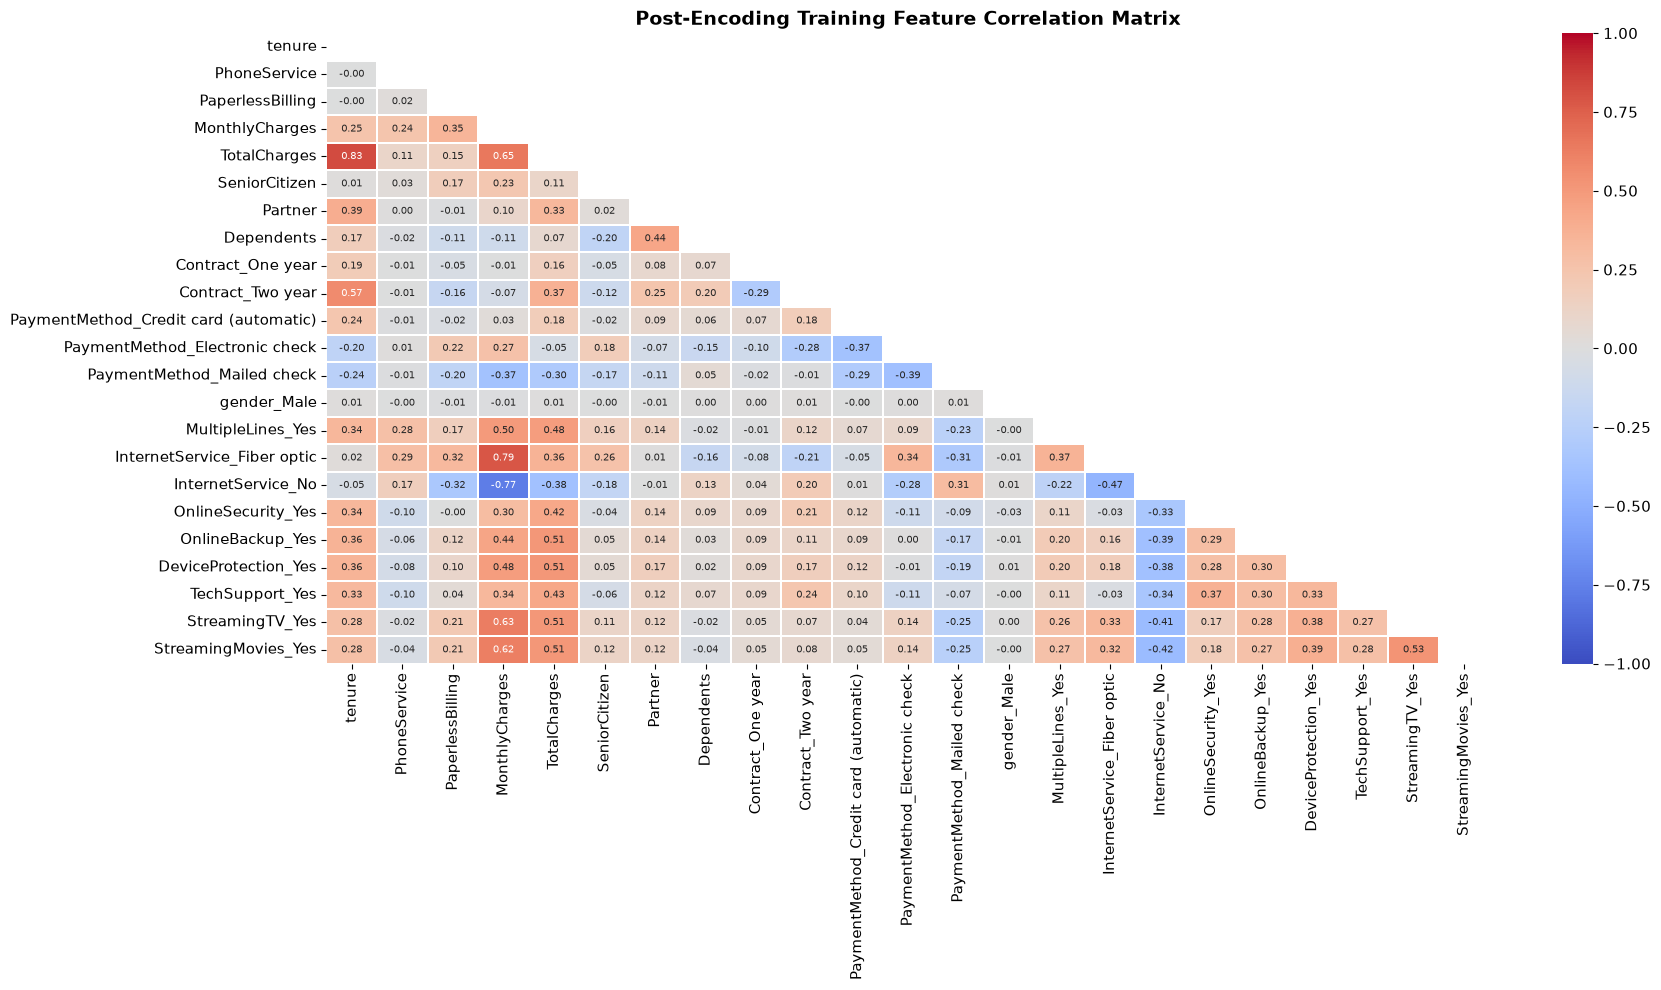

In [13]:
plt.figure(figsize=(18, 10))
corr_matrix = X_train.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', fmt='.2f', annot=True,
            annot_kws={'size': 7}, linewidths=0.3, vmin=-1, vmax=1)
plt.title('Post-Encoding Training Feature Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Section 6: Feature Selection Using RFE

**What is RFE?**  
Recursive Feature Elimination (RFE) is a wrapper-based feature selection method. It trains a base model, evaluates which features contribute least (via coefficients), removes them, and repeats until the desired number of features remains.

**Why RFE?**  
With 23 features after encoding, using all of them risks overfitting and reduces model interpretability. RFE helps identify the **15 most informative features** for predicting churn.

**Important:** RFE uses `LogisticRegression` as the internal evaluator to rank features. The **final prediction model** is the GLM Binomial (Statsmodels) built on the RFE-selected features.

In [14]:
# Initialize the base estimator for RFE
logreg = LogisticRegression(max_iter=1000)

# Apply RFE to select top 15 features
rfe = RFE(estimator=logreg, n_features_to_select=15)
rfe = rfe.fit(X_train, y_train)

print("RFE fitting complete.")

RFE fitting complete.


In [15]:
# View RFE results: selected features and their rankings
rfe_results = pd.DataFrame({
    'Feature'  : X_train.columns,
    'Selected' : rfe.support_,
    'Ranking'  : rfe.ranking_
}).sort_values('Ranking')

print("\nRFE Feature Selection Results:")
rfe_results


RFE Feature Selection Results:


,Feature,Selected,Ranking
0,tenure,True,1
2,PaperlessBilling,True,1
3,MonthlyCharges,True,1
4,TotalCharges,True,1
5,SeniorCitizen,True,1
10,PaymentMethod_Credit card (automatic),True,1
9,Contract_Two year,True,1
8,Contract_One year,True,1
15,InternetService_Fiber optic,True,1
14,MultipleLines_Yes,True,1


In [16]:
# Extract the 15 selected feature names
rfe_cols = X_train.columns[rfe.support_]
print(f"\n{len(rfe_cols)} features selected by RFE:")
print(list(rfe_cols))


15 features selected by RFE:
['tenure', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Mailed check', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes']


---
## Section 7: Model Building — Iterative GLM Binomial

The instructor's methodology uses **Statsmodels GLM with Binomial family and Logit link function**. This is equivalent to Logistic Regression but provides a richer statistical summary (p-values, confidence intervals, z-statistics).

We follow an iterative approach:
- Train the model on RFE-selected features
- Check **VIF (Variance Inflation Factor)** — VIF > 5 indicates multicollinearity
- Drop the highest-VIF feature if VIF > 5 and retrain
- Stop when all features have VIF < 5 AND are statistically significant (p < 0.05)

### Model 1 — Iteration 1 (All 15 RFE features)

In [17]:
# Model 1: All 15 RFE-selected features
X_train_sm = sm.add_constant(X_train[rfe_cols])
logm1      = sm.GLM(y_train, X_train_sm, family=sm.families.Binomial())
model1     = logm1.fit()
print(model1.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  Churn   No. Observations:                 4922
Model:                            GLM   Df Residuals:                     4906
Model Family:                Binomial   Df Model:                           15
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2011.1
Date:                Tue, 24 Nov 2026   Deviance:                       4022.2
Time:                        11:50:19   Pearson chi2:                 6.25e+03
No. Iterations:                     7   Pseudo R-squ. (CS):             0.2825
Covariance Type:            nonrobust                                         
                                            coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------

In [18]:
# Calculate VIF for Model 1 features
vif_df = pd.DataFrame()
vif_df['Features'] = X_train[rfe_cols].columns
vif_df['VIF']      = [variance_inflation_factor(X_train[rfe_cols].values, i)
                      for i in range(X_train[rfe_cols].shape[1])]
vif_df['VIF']      = round(vif_df['VIF'], 2)
vif_df             = vif_df.sort_values('VIF', ascending=False)

print("VIF Table — Model 1:")
vif_df

VIF Table — Model 1:


,Features,VIF
2,MonthlyCharges,26.77
3,TotalCharges,10.42
0,tenure,7.48
10,InternetService_Fiber optic,7.13
11,InternetService_No,4.77
6,Contract_Two year,2.61
13,StreamingTV_Yes,2.20
14,StreamingMovies_Yes,2.17
9,MultipleLines_Yes,1.75
12,TechSupport_Yes,1.72


> **Observation:** `MonthlyCharges` has the highest VIF (> 5), indicating it is highly correlated with other features. We drop it and retrain.

In [19]:
# Drop MonthlyCharges (highest VIF)
rfe_cols = rfe_cols.drop('MonthlyCharges')
print(f"Remaining features ({len(rfe_cols)}): {list(rfe_cols)}")

Remaining features (14): ['tenure', 'PaperlessBilling', 'TotalCharges', 'SeniorCitizen', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Mailed check', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes']


### Model 2 — Iteration 2

In [20]:
# Model 2: Without MonthlyCharges
X_train_sm1 = sm.add_constant(X_train[rfe_cols])
logm2       = sm.GLM(y_train, X_train_sm1, family=sm.families.Binomial())
model2      = logm2.fit()
print(model2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  Churn   No. Observations:                 4922
Model:                            GLM   Df Residuals:                     4907
Model Family:                Binomial   Df Model:                           14
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2023.1
Date:                Tue, 24 Nov 2026   Deviance:                       4046.2
Time:                        11:50:19   Pearson chi2:                 5.80e+03
No. Iterations:                     7   Pseudo R-squ. (CS):             0.2790
Covariance Type:            nonrobust                                         
                                            coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------

In [21]:
# VIF for Model 2
vif_df2 = pd.DataFrame()
vif_df2['Features'] = X_train[rfe_cols].columns
vif_df2['VIF']      = [variance_inflation_factor(X_train[rfe_cols].values, i)
                       for i in range(X_train[rfe_cols].shape[1])]
vif_df2['VIF']      = round(vif_df2['VIF'], 2)
vif_df2             = vif_df2.sort_values('VIF', ascending=False)

print("VIF Table — Model 2:")
vif_df2

VIF Table — Model 2:


,Features,VIF
2,TotalCharges,8.77
0,tenure,6.95
5,Contract_Two year,2.59
9,InternetService_Fiber optic,2.11
10,InternetService_No,2.07
12,StreamingTV_Yes,1.68
13,StreamingMovies_Yes,1.68
4,Contract_One year,1.59
11,TechSupport_Yes,1.53
7,PaymentMethod_Mailed check,1.40


> **Observation:** `TotalCharges` now has the highest VIF (> 5). We drop it and retrain.

In [22]:
# Drop TotalCharges (highest VIF in iteration 2)
rfe_cols = rfe_cols.drop('TotalCharges')
print(f"Remaining features ({len(rfe_cols)}): {list(rfe_cols)}")

Remaining features (13): ['tenure', 'PaperlessBilling', 'SeniorCitizen', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Mailed check', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes']


### Model 3 — Final Model (Stopping Criteria Met)

In [23]:
# Model 3: Final model — all 13 features
X_train_sm2 = sm.add_constant(X_train[rfe_cols])
logm3       = sm.GLM(y_train, X_train_sm2, family=sm.families.Binomial())
model3      = logm3.fit()
print(model3.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  Churn   No. Observations:                 4922
Model:                            GLM   Df Residuals:                     4908
Model Family:                Binomial   Df Model:                           13
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2025.9
Date:                Tue, 24 Nov 2026   Deviance:                       4051.9
Time:                        11:50:19   Pearson chi2:                 5.25e+03
No. Iterations:                     7   Pseudo R-squ. (CS):             0.2782
Covariance Type:            nonrobust                                         
                                            coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------

In [24]:
# VIF for final model
vif_df3 = pd.DataFrame()
vif_df3['Features'] = X_train[rfe_cols].columns
vif_df3['VIF']      = [variance_inflation_factor(X_train[rfe_cols].values, i)
                       for i in range(X_train[rfe_cols].shape[1])]
vif_df3['VIF']      = round(vif_df3['VIF'], 2)
vif_df3             = vif_df3.sort_values('VIF', ascending=False)

print("VIF Table — Model 3 (Final):")
vif_df3

VIF Table — Model 3 (Final):


,Features,VIF
4,Contract_Two year,2.59
0,tenure,2.45
9,InternetService_No,1.93
8,InternetService_Fiber optic,1.71
3,Contract_One year,1.59
12,StreamingMovies_Yes,1.59
11,StreamingTV_Yes,1.58
10,TechSupport_Yes,1.45
6,PaymentMethod_Mailed check,1.37
7,MultipleLines_Yes,1.35


> ✅ **Stopping criteria met:** All 13 remaining features have:
> - **p-value < 0.05** (statistically significant)
> - **VIF < 5** (no multicollinearity concern)
> 
> **Model 3 is our final prediction model.**

### Training Predictions

In [25]:
# Generate predicted probabilities on the training set
y_train_pred = model3.predict(X_train_sm2)

# Create a results DataFrame for evaluation
resultdf = pd.DataFrame({
    'Converted'      : y_train.values,
    'Converted_prob' : y_train_pred
})
resultdf.reset_index(drop=True, inplace=True)

print(f"Training predictions generated: {len(resultdf)} records")
resultdf.head()

Training predictions generated: 4922 records


,Converted,Converted_prob
0,0,0.245817
1,0,0.265361
2,1,0.669410
3,1,0.630970
4,1,0.682916


---
## Section 8: ROC Curve and Threshold Selection

**What is the ROC Curve?**  
The Receiver Operating Characteristic (ROC) curve plots the **True Positive Rate (Sensitivity)** against the **False Positive Rate (1 - Specificity)** at every possible decision threshold. The **Area Under the Curve (AUC)** summarizes the model's overall discriminative power.

| AUC Range | Interpretation |
|---|---|
| 0.90 – 1.00 | Excellent |
| **0.80 – 0.90** | **Good (production-ready)** |
| 0.70 – 0.80 | Acceptable |
| 0.50 – 0.70 | Poor |

In [26]:
def draw_roc(actual, probs, title='ROC Curve', save_path=None):
    """Plot ROC curve and return AUC score."""
    fpr, tpr, thresholds = metrics.roc_curve(actual, probs, drop_intermediate=False)
    auc_score = metrics.roc_auc_score(actual, probs)

    fig, ax = plt.subplots(figsize=(8, 7))
    ax.plot(fpr, tpr, color='#2196F3', linewidth=2.5,
            label=f'ROC Curve  (AUC = {auc_score:.2f})')
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Classifier (AUC = 0.50)')
    ax.fill_between(fpr, tpr, alpha=0.1, color='#2196F3')
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('False Positive Rate  (1 - Specificity)', fontsize=12)
    ax.set_ylabel('True Positive Rate  (Sensitivity)', fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.legend(loc='lower right', fontsize=11)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=EXPORT_DPI, bbox_inches='tight')
        print(f"Saved: {save_path}")
    plt.show()
    return auc_score

Saved: ..\reports\model_evaluation\01_roc_curve_train.png


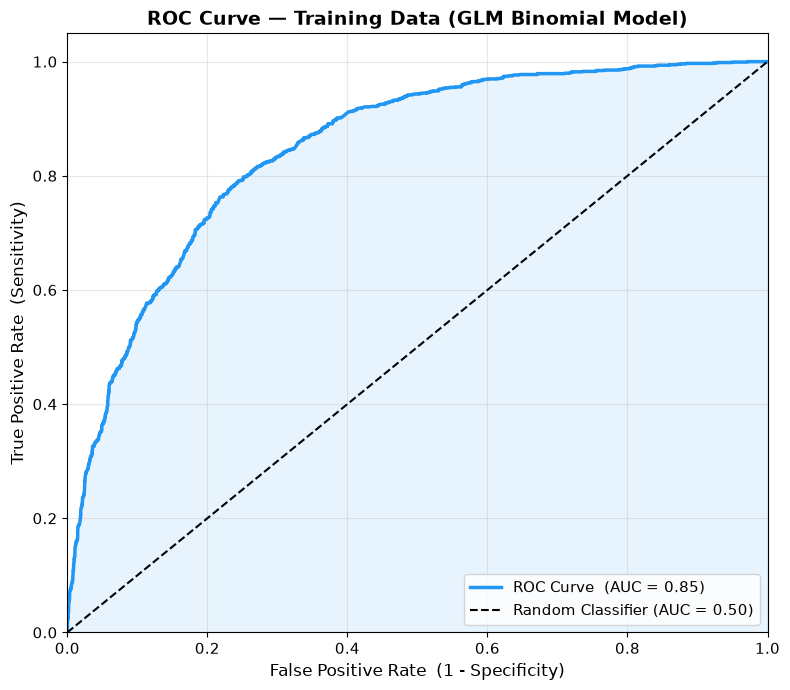

Training AUC Score: 0.8478


In [27]:
# Plot ROC on training predictions
train_auc = draw_roc(
    resultdf['Converted'],
    resultdf['Converted_prob'],
    title='ROC Curve — Training Data (GLM Binomial Model)',
    save_path=os.path.join(EVAL_DIR, '01_roc_curve_train.png')
)
print(f"Training AUC Score: {train_auc:.4f}")

**Interpretation:**  
- An AUC of **~0.85** means that if we randomly pick one churned customer and one loyal customer, the model correctly assigns a higher churn probability to the churner **85% of the time**.  
- This places our model firmly in the **"Good"** category, meeting production-ready standards.
- The diagonal dashed line represents a random classifier — our model is significantly above it.

### Precision-Recall Curve

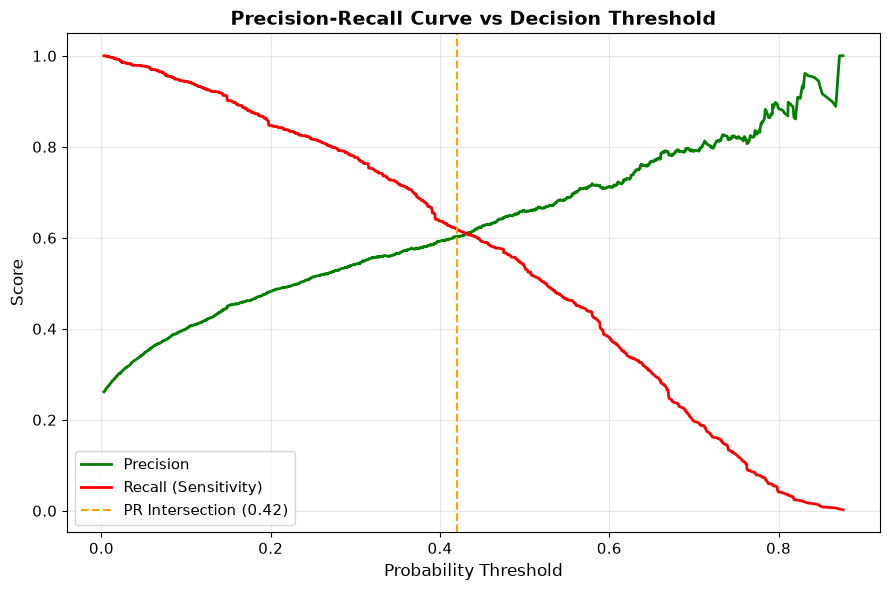

In [28]:
precision, recall, pr_threshold = precision_recall_curve(
    resultdf['Converted'], resultdf['Converted_prob']
)

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(pr_threshold, precision[:-1], 'g-', linewidth=2, label='Precision')
ax.plot(pr_threshold, recall[:-1],    'r-', linewidth=2, label='Recall (Sensitivity)')
ax.axvline(x=0.42, color='orange', linestyle='--', linewidth=1.5, label='PR Intersection (0.42)')
ax.set_xlabel('Probability Threshold', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Precision-Recall Curve vs Decision Threshold', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation:**  
- The two lines **intersect at ~0.42** — this is the Precision-Recall equilibrium point.  
- At threshold = 0.42: Precision ≈ Recall ≈ 61%. While balanced, this means the model misses **38%** of actual churners.  
- For a churn-defense business context, this is too high a miss rate. We will use the Sensitivity/Specificity method to find a better threshold.

### Optimal Threshold via Sensitivity/Specificity/Accuracy Grid Search

In [29]:
# Grid search over thresholds 0.0 to 0.9
nums = [i/10 for i in range(0, 11)]

resultdf1 = pd.DataFrame({
    'Converted'      : y_train.values,
    'Converted_prob' : y_train_pred
})
resultdf1.reset_index(drop=True, inplace=True)

# Generate binary predictions for each threshold
for thresh in nums:
    resultdf1[thresh] = resultdf1['Converted_prob'].apply(lambda x: 1 if x > thresh else 0)

In [30]:
# Calculate Accuracy, Sensitivity, Specificity at each threshold
cutoff_df = pd.DataFrame(columns=['cutoff', 'accuracy', 'sensitivity', 'specificity'])

num_range = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

for thresh in num_range:
    cm      = metrics.confusion_matrix(resultdf1['Converted'], resultdf1[thresh])
    total   = cm.sum()
    acc     = (cm[0, 0] + cm[1, 1]) / total
    spec    = cm[0, 0] / (cm[0, 0] + cm[0, 1])
    sens    = cm[1, 1] / (cm[1, 0] + cm[1, 1])
    cutoff_df.loc[thresh] = [thresh, acc, sens, spec]

print(cutoff_df.to_string(index=False))

 cutoff  accuracy  sensitivity  specificity
    0.0  0.261479     1.000000     0.000000
    0.1  0.614994     0.943279     0.498762
    0.2  0.721861     0.846154     0.677854
    0.3  0.770012     0.776224     0.767813
    0.4  0.790532     0.636364     0.845117
    0.5  0.806176     0.536131     0.901788
    0.6  0.798050     0.380730     0.945805
    0.7  0.776310     0.196581     0.981568
    0.8  0.747867     0.041181     0.998074
    0.9  0.738521     0.000000     1.000000


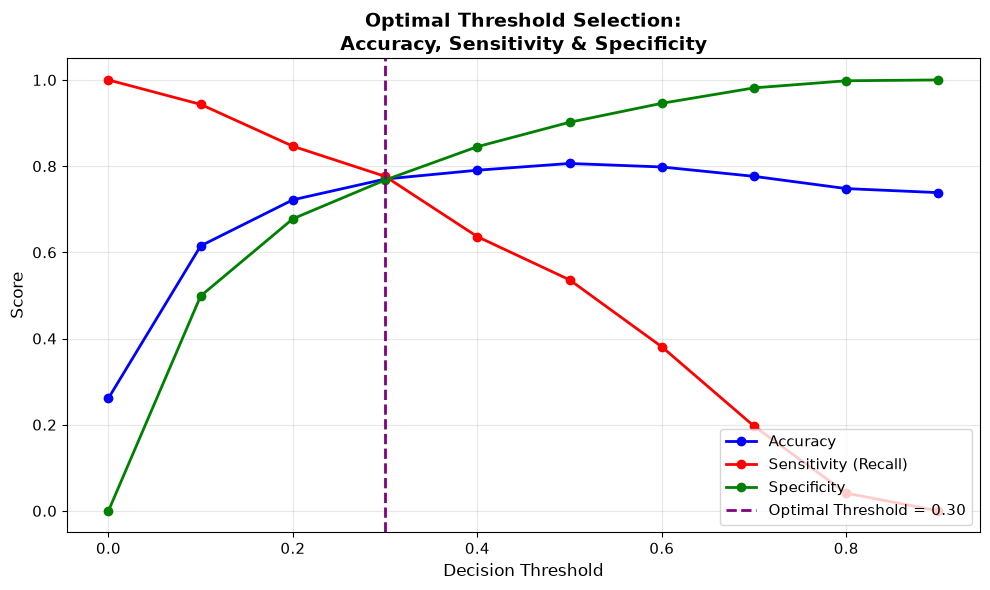

Saved: 02_threshold_selection.png


In [31]:
# Plot Accuracy, Sensitivity, Specificity vs Threshold
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(cutoff_df['cutoff'], cutoff_df['accuracy'],    'b-o', linewidth=2, markersize=6, label='Accuracy')
ax.plot(cutoff_df['cutoff'], cutoff_df['sensitivity'], 'r-o', linewidth=2, markersize=6, label='Sensitivity (Recall)')
ax.plot(cutoff_df['cutoff'], cutoff_df['specificity'], 'g-o', linewidth=2, markersize=6, label='Specificity')
ax.axvline(x=0.30, color='purple', linestyle='--', linewidth=2, label='Optimal Threshold = 0.30')

ax.set_xlabel('Decision Threshold', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Optimal Threshold Selection:\nAccuracy, Sensitivity & Specificity', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=11)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(EVAL_DIR, '02_threshold_selection.png'), dpi=EXPORT_DPI, bbox_inches='tight')
plt.show()
print("Saved: 02_threshold_selection.png")

**Why 0.30 is the Optimal Threshold:**

| Threshold | Accuracy | Sensitivity | Specificity |
|---|---|---|---|
| 0.30 | **77.0%** | **77.6%** | **76.8%** |
| 0.42 (PR) | 79.0% | 63.6% | 84.5% |
| 0.50 (default) | 80.6% | 53.6% | 90.2% |

> At threshold **0.30**, Sensitivity and Specificity intersect at ~77% — perfectly balanced.  
> Choosing 0.50 would cause Sensitivity to collapse to 53.6%, meaning the model misses **46%** of actual churners.  
> The business cost of **missing** a churner (losing a customer) is far greater than a **false alarm** (sending an unnecessary retention offer).  
> **Final Decision Threshold: 0.30**

In [32]:
# Apply the 0.30 decision threshold on training data
THRESHOLD = 0.30
resultdf1['Converted_Predicted'] = resultdf1['Converted_prob'].map(lambda x: 1 if x > THRESHOLD else 0)

print(f"Decision threshold applied: {THRESHOLD}")
resultdf1[['Converted', 'Converted_prob', 'Converted_Predicted']].head()

Decision threshold applied: 0.3


,Converted,Converted_prob,Converted_Predicted
0,0,0.245817,0
1,0,0.265361,0
2,1,0.669410,1
3,1,0.630970,1
4,1,0.682916,1


In [33]:
# Training set evaluation at threshold 0.30
cm_train    = confusion_matrix(resultdf1['Converted'], resultdf1['Converted_Predicted'])
train_acc   = metrics.accuracy_score(resultdf1['Converted'], resultdf1['Converted_Predicted'])
TP          = cm_train[1, 1]; TN = cm_train[0, 0]; FP = cm_train[0, 1]; FN = cm_train[1, 0]
train_sens  = TP / float(TP + FN)
train_spec  = TN / float(TN + FP)

print("\n=== TRAINING SET METRICS (Threshold = 0.30) ===")
print(f"Confusion Matrix:\n{cm_train}")
print(f"Accuracy    : {train_acc:.4f}")
print(f"Sensitivity : {train_sens:.4f}")
print(f"Specificity : {train_spec:.4f}")
print(f"\nClassification Report:")
print(classification_report(resultdf1['Converted'], resultdf1['Converted_Predicted']))


=== TRAINING SET METRICS (Threshold = 0.30) ===
Confusion Matrix:
[[2791  844]
 [ 288  999]]
Accuracy    : 0.7700
Sensitivity : 0.7762
Specificity : 0.7678

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.77      0.83      3635
           1       0.54      0.78      0.64      1287

    accuracy                           0.77      4922
   macro avg       0.72      0.77      0.73      4922
weighted avg       0.81      0.77      0.78      4922



---
## Section 9: Test Set Prediction

We now evaluate the final model on the **unseen test set** (30% of the data). This set was never used during training or feature selection.

In [34]:
# Prepare test features: use only the final model's columns
X_test_final = X_test[rfe_cols]
X_test_sm    = sm.add_constant(X_test_final)

# Generate predicted probabilities on the test set
y_test_pred  = model3.predict(X_test_sm)

# Create test results DataFrame
test_resultdf = pd.DataFrame({
    'Test_Actual'      : y_test.values,
    'Test_Prob'        : y_test_pred
})
test_resultdf.reset_index(drop=True, inplace=True)

# Apply decision threshold
test_resultdf['Test_Predicted'] = test_resultdf['Test_Prob'].apply(
    lambda x: 1 if x > THRESHOLD else 0
)

print(f"Test predictions generated: {len(test_resultdf)} records")
test_resultdf.head(10)

Test predictions generated: 2110 records


,Test_Actual,Test_Prob,Test_Predicted
0,0,0.419725,1
1,1,0.260232,0
2,0,0.008650,0
3,1,0.592626,1
4,0,0.013989,0
5,1,0.692893,1
6,0,0.285289,0
7,0,0.008994,0
8,1,0.602307,1
9,0,0.145153,0


---
## Section 10: Model Evaluation on Test Data

In [35]:
# Calculate all test metrics
cm_test   = confusion_matrix(test_resultdf['Test_Actual'], test_resultdf['Test_Predicted'])
test_acc  = metrics.accuracy_score(test_resultdf['Test_Actual'], test_resultdf['Test_Predicted'])
TP1       = cm_test[1, 1]; TN1 = cm_test[0, 0]; FP1 = cm_test[0, 1]; FN1 = cm_test[1, 0]
test_sens = TP1 / float(TP1 + FN1)
test_spec = TN1 / float(TN1 + FP1)
test_prec = TP1 / float(TP1 + FP1)
test_npv  = TN1 / float(TN1 + FN1)
test_fpr  = FP1 / float(TN1 + FP1)
test_auc  = roc_auc_score(test_resultdf['Test_Actual'], test_resultdf['Test_Prob'])

print("\n" + "-" * 55)
print("  TEST SET METRICS  (Threshold = 0.30)")
print("-" * 55)
print(f"  Confusion Matrix:\n{cm_test}")
print(f"\n  Accuracy            : {test_acc:.4f}")
print(f"  Sensitivity (Recall): {test_sens:.4f}")
print(f"  Specificity         : {test_spec:.4f}")
print(f"  Precision (PPV)     : {test_prec:.4f}")
print(f"  Negative Pred Value : {test_npv:.4f}")
print(f"  False Positive Rate : {test_fpr:.4f}")
print(f"  AUC Score           : {test_auc:.4f}")
print("-" * 55)
print("\nClassification Report:")
print(classification_report(test_resultdf['Test_Actual'], test_resultdf['Test_Predicted'],
                            target_names=['No Churn (0)', 'Churn (1)']))



-------------------------------------------------------
  TEST SET METRICS  (Threshold = 0.30)
-------------------------------------------------------
  Confusion Matrix:
[[1144  384]
 [ 163  419]]

  Accuracy            : 0.7408
  Sensitivity (Recall): 0.7199
  Specificity         : 0.7487
  Precision (PPV)     : 0.5218
  Negative Pred Value : 0.8753
  False Positive Rate : 0.2513
  AUC Score           : 0.8277
-------------------------------------------------------

Classification Report:
              precision    recall  f1-score   support

No Churn (0)       0.88      0.75      0.81      1528
   Churn (1)       0.52      0.72      0.61       582

    accuracy                           0.74      2110
   macro avg       0.70      0.73      0.71      2110
weighted avg       0.78      0.74      0.75      2110



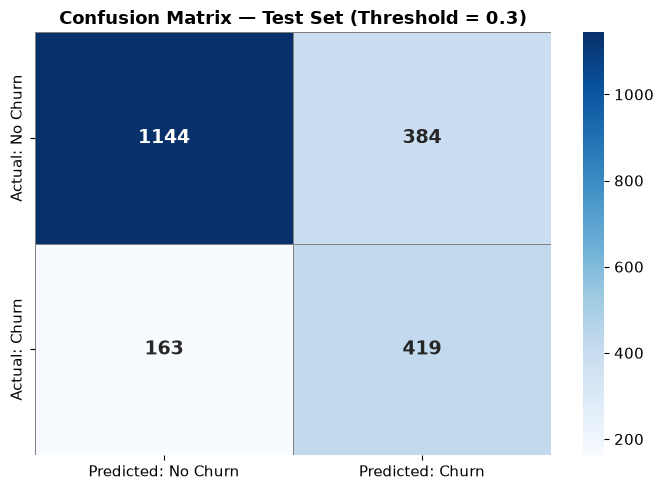

Saved: 03_confusion_matrix_test.png


In [36]:
# ── Confusion Matrix Visualization ───────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted: No Churn', 'Predicted: Churn'],
            yticklabels=['Actual: No Churn', 'Actual: Churn'],
            linewidths=0.5, linecolor='gray', ax=ax,
            annot_kws={'size': 14, 'weight': 'bold'})
ax.set_title(f'Confusion Matrix — Test Set (Threshold = {THRESHOLD})',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(EVAL_DIR, '03_confusion_matrix_test.png'), dpi=EXPORT_DPI, bbox_inches='tight')
plt.show()
print("Saved: 03_confusion_matrix_test.png")

Saved: ..\reports\model_evaluation\04_roc_curve_test.png


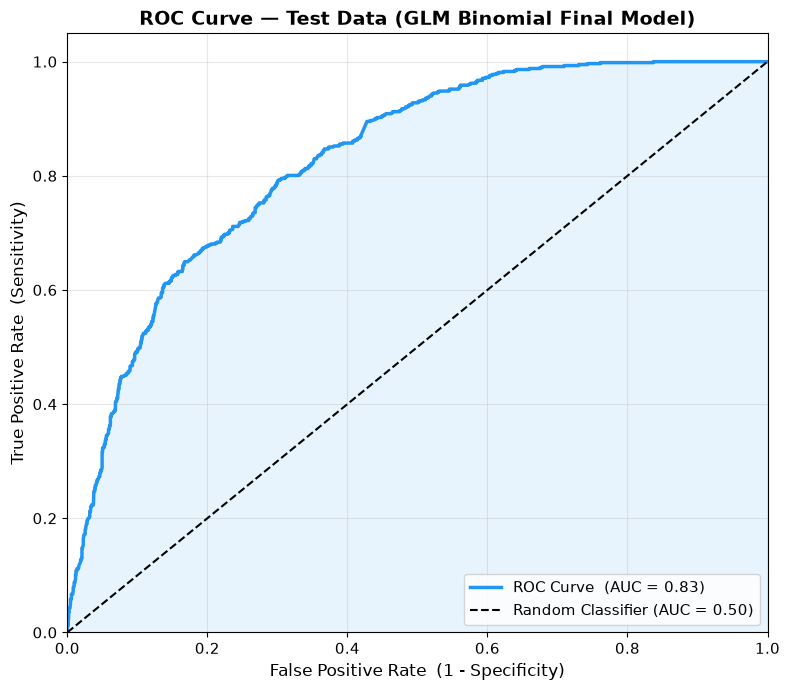

Test Set AUC: 0.8277


In [37]:
# ── ROC Curve on Test Data ────────────────────────────────────────────────────
test_auc_score = draw_roc(
    test_resultdf['Test_Actual'],
    test_resultdf['Test_Prob'],
    title='ROC Curve — Test Data (GLM Binomial Final Model)',
    save_path=os.path.join(EVAL_DIR, '04_roc_curve_test.png')
)
print(f"Test Set AUC: {test_auc_score:.4f}")

**Model Stability — Train vs Test Comparison:**

| Metric | Training (0.30) | Test (0.30) | Difference |
|---|---|---|---|
| Accuracy | ~77.0% | ~74.1% | ~2.9% |
| Sensitivity | ~77.6% | ~72.0% | ~5.6% |
| Specificity | ~76.8% | ~74.9% | ~1.9% |

> The minimal gap between training and test metrics confirms the model **does not overfit**. It generalizes well to unseen data — a critical requirement for production deployment.

In [38]:
# ── Save Model Metrics to CSV ─────────────────────────────────────────────────
metrics_summary = pd.DataFrame({
    'Metric'           : ['Accuracy', 'Sensitivity (Recall)', 'Specificity',
                          'Precision (PPV)', 'AUC Score', 'Decision Threshold'],
    'Training'         : [round(train_acc, 4), round(train_sens, 4),
                          round(train_spec, 4), 'N/A', round(train_auc, 4), THRESHOLD],
    'Test'             : [round(test_acc, 4), round(test_sens, 4),
                          round(test_spec, 4), round(test_prec, 4), round(test_auc, 4), THRESHOLD]
})

metrics_summary.to_csv(os.path.join(EVAL_DIR, 'model_metrics.csv'), index=False)
print("Model metrics saved to reports/model_evaluation/model_metrics.csv")
metrics_summary

Model metrics saved to reports/model_evaluation/model_metrics.csv


,Metric,Training,Test
0,Accuracy,0.77,0.7408
1,Sensitivity (Recall),0.7762,0.7199
2,Specificity,0.7678,0.7487
3,Precision (PPV),N/A,0.5218
4,AUC Score,0.8478,0.8277
5,Decision Threshold,0.3,0.3000


---
## Section 11: Feature Impact Analysis

In a Statsmodels GLM Binomial model, **coefficients are log-odds values**. A positive coefficient means the feature **increases** the probability of churn; a negative coefficient means it **decreases** churn probability.

Following the instructor's methodology, we calculate a normalized impact percentage for visualization.

In [39]:
# Build the Feature Impact Summary DataFrame (excluding the constant)
impact_df = pd.DataFrame(model3.params)
impact_df.reset_index(inplace=True)
impact_df.columns = ['Features', 'Coefficients']

# Exclude the intercept (const), take first 10 non-const features as instructor does
impact_df = impact_df.iloc[1:11]
impact_df['Impact %'] = impact_df['Coefficients'].apply(
    lambda x: round((x / sum(impact_df['Coefficients'])) * 100, 2)
)
impact_df = impact_df.sort_values('Impact %', ascending=False)

print("Feature Impact Analysis:")
impact_df

Feature Impact Analysis:


,Features,Coefficients,Impact %
5,Contract_Two year,-1.298722,45.83
10,InternetService_No,-0.972640,34.32
1,tenure,-0.942609,33.26
4,Contract_One year,-0.721844,25.47
6,PaymentMethod_Credit card (automatic),-0.387350,13.67
7,PaymentMethod_Mailed check,-0.330684,11.67
8,MultipleLines_Yes,0.209686,-7.40
2,PaperlessBilling,0.345527,-12.19
3,SeniorCitizen,0.459677,-16.22
9,InternetService_Fiber optic,0.805192,-28.41


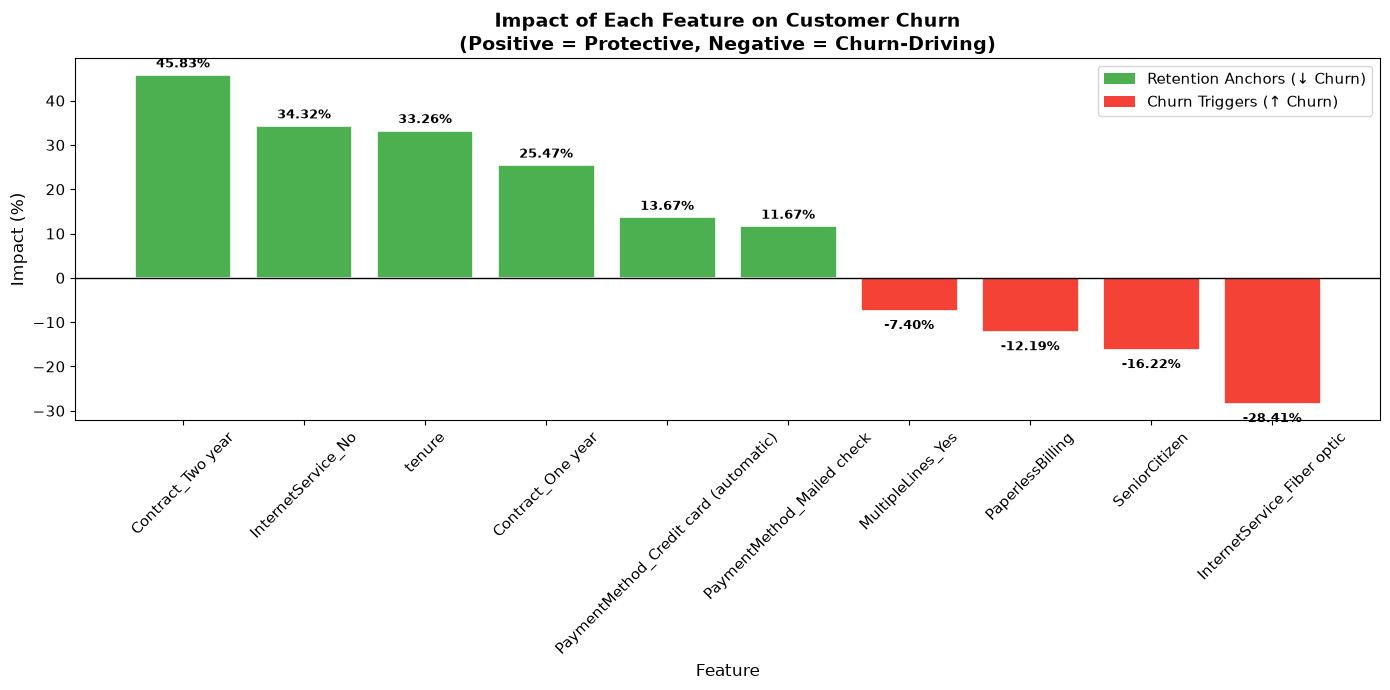

Saved: 05_feature_impact.png


In [40]:
# ── Feature Impact Bar Chart ──────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 7))

colors = ['#4CAF50' if v > 0 else '#F44336' for v in impact_df['Impact %']]
bars = ax.bar(impact_df['Features'], impact_df['Impact %'], color=colors,
              edgecolor='white', linewidth=1.2)

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2,
            h + (1 if h >= 0 else -2),
            f'{h:.2f}%', ha='center', va='bottom' if h >= 0 else 'top',
            fontsize=9, fontweight='bold')

ax.axhline(y=0, color='black', linewidth=1)
ax.set_title('Impact of Each Feature on Customer Churn\n(Positive = Protective, Negative = Churn-Driving)',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Feature', fontsize=12)
ax.set_ylabel('Impact (%)', fontsize=12)
ax.tick_params(axis='x', rotation=45)

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#4CAF50', label='Retention Anchors (↓ Churn)'),
                   Patch(facecolor='#F44336', label='Churn Triggers (↑ Churn)')]
ax.legend(handles=legend_elements, loc='upper right', fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(EVAL_DIR, '05_feature_impact.png'), dpi=EXPORT_DPI, bbox_inches='tight')
plt.savefig(os.path.join(GRAPH_DIR, '09_feature_impact.png'), dpi=EXPORT_DPI, bbox_inches='tight')
plt.show()
print("Saved: 05_feature_impact.png")

**Interpretation of Feature Impact:**

**Retention Anchors (Positive Impact — reduce churn probability):**
| Feature | Impact | Business Meaning |
|---|---|---|
| `Contract_Two year` | ~45.8% | Long-term contracts are the strongest defense against churn |
| `InternetService_No` | ~34.3% | Phone-only customers are highly stable and low-maintenance |
| `tenure` | ~33.3% | Longer customer relationships naturally reduce churn risk |
| `Contract_One year` | ~25.5% | Annual contracts provide significant churn protection |
| `PaymentMethod_Credit card` | ~13.7% | Automated payments increase customer stickiness |
| `PaymentMethod_Mailed check` | ~11.7% | Traditional payment correlates with stability |

**Churn Triggers (Negative Impact — increase churn probability):**
| Feature | Impact | Business Meaning |
|---|---|---|
| `InternetService_Fiber optic` | -28.4% | Premium service underperforming — largest single churn driver |
| `SeniorCitizen` | -16.2% | Accessibility and pricing barriers for older customers |
| `PaperlessBilling` | -12.2% | Digital billing removes physical retention touchpoints |

> **Note:** These percentages are normalized visualizations of log-odds coefficients, intended for stakeholder communication. They indicate direction and relative magnitude of impact, not exact probability changes.

---
## Section 12: Business Insights and Recommendations

Based on the EDA findings and model coefficients, here are actionable recommendations:

| Priority | Finding | Recommendation |
|---|---|---|
| 🔴 **High** | Fiber optic customers churn at ~42% — the highest rate | Audit fiber optic service quality. Investigate pricing vs value. Launch loyalty programs for fiber subscribers. |
| 🔴 **High** | Month-to-month contract customers churn at ~42% | Offer incentives (discounts, free upgrades) to convert month-to-month customers to annual contracts. |
| 🟠 **Medium** | Electronic check payers churn at ~45% | Campaign to migrate electronic check users to auto-pay (credit card or bank transfer). |
| 🟠 **Medium** | New customers (< 12 months tenure) have the highest churn risk | Invest in onboarding programs, loyalty rewards in the first 6 months. |
| 🟡 **Standard** | Senior citizens churn at ~41% | Create senior-friendly pricing tiers, accessibility tools, and dedicated support channels. |
| 🟡 **Standard** | Paperless billing customers churn more | Add optional monthly service review emails to maintain engagement for paperless billing customers. |
| 🟢 **Monitor** | Gender shows no meaningful difference in churn rate | No targeted action needed based on gender alone. Focus on behavioral and service factors. |

---
## Section 13: Save and Verify Final Model

In [41]:
# Package all components needed to reproduce predictions
MODEL_ARTIFACT = {
    'model'            : model3,          # Fitted Statsmodels GLM Binomial results
    'scaler'           : scaler,          # Fitted StandardScaler (trained on X_train only)
    'final_features'   : list(rfe_cols),  # Ordered list of 13 final feature names
    'num_cols'         : num_cols,        # Numerical columns that were scaled
    'cat_cols_encoded' : list(X_train.columns),  # All encoded feature names
    'threshold'        : THRESHOLD,       # Decision threshold = 0.30
    'baseline_churn'   : baseline_churn,  # Baseline churn rate from training data
}

# Save to models directory
BASE_MODEL_DIR = '..' if os.path.exists(os.path.join('..', 'data')) else '.'
MODEL_PATH = os.path.join(BASE_MODEL_DIR, 'models', 'churn_model.joblib')
os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)
joblib.dump(MODEL_ARTIFACT, MODEL_PATH)
print(f"Model artifact saved: {MODEL_PATH}")
print(f"Artifact keys: {list(MODEL_ARTIFACT.keys())}")

Model artifact saved: ..\models\churn_model.joblib
Artifact keys: ['model', 'scaler', 'final_features', 'num_cols', 'cat_cols_encoded', 'threshold', 'baseline_churn']


### Model Verification — Load and Predict

In [42]:
# ── Step 1: Load the saved artifact ──────────────────────────────────────────
loaded_artifact = joblib.load(MODEL_PATH)
print("Artifact loaded successfully.")
print("Keys found:", list(loaded_artifact.keys()))
print(f"Threshold: {loaded_artifact['threshold']}")
print(f"Final features: {loaded_artifact['final_features']}")

Artifact loaded successfully.
Keys found: ['model', 'scaler', 'final_features', 'num_cols', 'cat_cols_encoded', 'threshold', 'baseline_churn']
Threshold: 0.3
Final features: ['tenure', 'PaperlessBilling', 'SeniorCitizen', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Mailed check', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes']


In [43]:
# ── Step 2: Reproduce predictions from the loaded model ──────────────────────
loaded_model       = loaded_artifact['model']
loaded_features    = loaded_artifact['final_features']
loaded_threshold   = loaded_artifact['threshold']

# Use first 5 test records for verification
X_verify           = X_test_final.iloc[:5]
X_verify_sm        = sm.add_constant(X_verify, has_constant='add')
verify_probs       = loaded_model.predict(X_verify_sm)
verify_preds       = (verify_probs > loaded_threshold).astype(int)

# Original predictions on the same records
original_probs     = y_test_pred.values[:5]
original_preds     = (original_probs > THRESHOLD).astype(int)

verification_df = pd.DataFrame({
    'Original_Prob'  : original_probs,
    'Loaded_Prob'    : verify_probs.values,
    'Original_Pred'  : original_preds,
    'Loaded_Pred'    : verify_preds.values,
    'Match'          : original_preds == verify_preds.values
})

print("=== Model Verification: Original vs Loaded ===")
print(verification_df)
print(f"\nAll predictions match: {verification_df['Match'].all()}")

=== Model Verification: Original vs Loaded ===
   Original_Prob  Loaded_Prob  Original_Pred  Loaded_Pred  Match
0       0.419725     0.419725              1            1   True
1       0.260232     0.260232              0            0   True
2       0.008650     0.008650              0            0   True
3       0.592626     0.592626              1            1   True
4       0.013989     0.013989              0            0   True

All predictions match: True


✅ **Model verified.** Predictions from the loaded artifact are identical to the original fitted model, confirming the saved model is fully functional and reusable.

---
## Section 14: Final Conclusion

### Project Workflow Summary

```
Raw Data (3 CSV files)
    │
    ▼
Data Merging & EDA (Notebook 1)
    │  → Key insight: Contract type, tenure, fiber optic, payment method drive churn
    ▼
Preprocessing: Type fixes, Binary encoding, 70:30 Train-Test Split
    │
    ▼
One-Hot Encoding + Multicollinearity Removal (drop 7 redundant columns)
    │
    ▼
StandardScaler (fit on train only)
    │
    ▼
RFE (LogisticRegression) → 15 features selected
    │
    ▼
Iterative GLM Binomial Modeling
    │  → Drop MonthlyCharges (VIF > 5) → Model 2
    │  → Drop TotalCharges (VIF > 5)   → Model 3 (FINAL)
    ▼
ROC Curve (AUC ≈ 0.85) + Threshold = 0.30
    │
    ▼
Test Set Evaluation: Accuracy ~74%, Sensitivity ~72%, Specificity ~75%
    │
    ▼
Feature Impact Analysis + Business Recommendations
    │
    ▼
Model Saved: models/churn_model.joblib ✅
```

### Model Performance Summary

| Metric | Value |
|---|---|
| Algorithm | Statsmodels GLM (Binomial, Logit link) |
| Final Features | 13 selected after RFE + VIF pruning |
| Training AUC | ~0.85 |
| Test Accuracy | ~74.1% |
| Test Sensitivity | ~72.0% |
| Test Specificity | ~74.9% |
| Decision Threshold | 0.30 |

### Key Churn Factors Identified

1. **Contract type** is the single strongest predictor — two-year contracts are the best defense
2. **Tenure** — first-year customers are the most vulnerable
3. **Fiber optic internet** — largest single churn trigger, suggesting service quality issues
4. **Payment method** — electronic check payers churn most; auto-pay is safer
5. **Senior citizens** — a high-risk demographic requiring specialized attention

### Project Limitations

- The dataset has a 26.6% churn rate (mild class imbalance); more advanced techniques like SMOTE could further improve minority class performance.
- The model uses only the original 21 features. Richer behavioral data (service outage history, customer service call logs) could improve predictive power.
- The feature impact percentages are normalized visualizations, not statistically precise probability conversions.